In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math
from IPython.display import Audio
import scipy

# Transformée de Fourier

## FFT d'un sinus

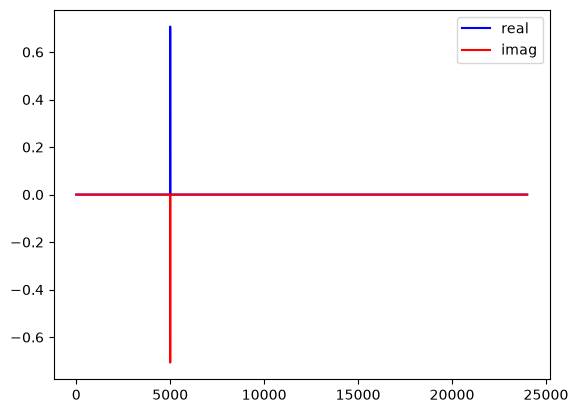

In [5]:
# init locals
fs = 48000

# create sine
duration_in_sec = 1
f1 = 5000
t = np.arange(duration_in_sec * fs) / fs
x = np.sin(2*math.pi*f1*t + math.pi/4)

# fft
n = len(x)
X = np.fft.rfft(x, n) / (n/2)
f = np.fft.rfftfreq(n, 1/fs)

# plot
plt.plot(f, np.real(X), color = 'blue', label = 'real')
plt.plot(f, np.imag(X), color = 'red', label = 'imag')

# format plot
plt.legend()
plt.show()

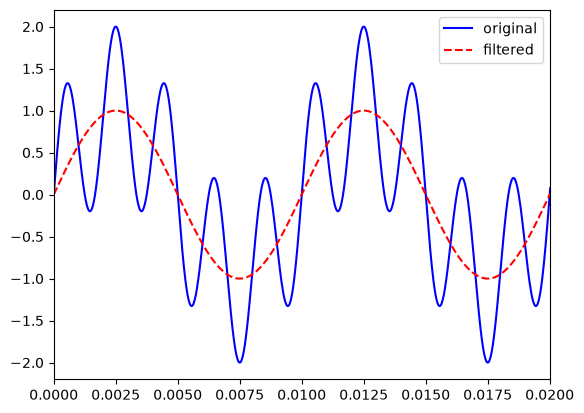

In [4]:
# init locals
fs = 48000

# create sine
duration_in_sec = 1
t = np.arange(duration_in_sec * fs) / fs
f1, f2 = 100, 500
x1 = np.sin(2*math.pi*f1*t)
x2 = np.sin(2*math.pi*f2*t)
x = x1+x2

# fft
n = len(x)
X = np.fft.rfft(x, n)
f = np.fft.rfftfreq(n, 1/fs)

# filter
W = np.zeros(len(X))
W[f<300] = 1
Y = W * X

# ifft
y = np.fft.irfft(Y, n)

# plot
plt.plot(t, x, color = 'blue', label = 'original')
plt.plot(t, y, color = 'red', label = 'filtered', linestyle = '--')

# format plot
plt.xlim([0, 2/f1])
plt.legend()
plt.show()

# play 
display(Audio(y, rate=fs))
